# SMS Spam Detection — LR vs NB

Same UCI SMS spam corpus as the email notebook, but the question I cared about this time was: does logistic regression actually beat Multinomial NB on this dataset, or is it just the usual "deep learning paper baseline" thing where people assume LR > NB and never actually check?

Answer: for short text with this much spam-marker vocabulary, they're really close. NB is a percent or two behind on accuracy but trains in a tenth of the time.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

np.random.seed(0)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
DATA_DIR = Path("../../data/sms_spam")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Auto-download the UCI SMS Spam Collection on first run.
import urllib.request, zipfile, io
csv_path = DATA_DIR / "SMSSpamCollection"
if not csv_path.exists():
    url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    print(f"downloading from {url}")
    with urllib.request.urlopen(url) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
        z.extractall(DATA_DIR)
    print("done ->", list(DATA_DIR.iterdir()))


downloading from https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip


done -> [PosixPath('../../data/sms_spam/readme'), PosixPath('../../data/sms_spam/SMSSpamCollection'), PosixPath('../../data/sms_spam/README.txt')]


In [2]:
for fname in ["SMSSpamCollection", "SMSSpamCollection.txt", "spam.csv"]:
    p = DATA_DIR / fname
    if p.exists():
        if fname.endswith(".csv"):
            df = pd.read_csv(p, encoding="latin-1")
            df = df[[c for c in df.columns if not c.startswith("Unnamed")]]
            df.columns = ["label", "message"][:len(df.columns)]
        else:
            df = pd.read_csv(p, sep="\t", names=["label", "message"], encoding="latin-1")
        break
else:
    raise FileNotFoundError("No SMS spam file in data/sms_spam/")

df["label"] = (df["label"].str.lower() == "spam").astype(int)
df = df.dropna(subset=["message"]).reset_index(drop=True)
print(df.shape, "  spam rate:", round(df["label"].mean(), 3))


(5572, 2)   spam rate: 0.134


## Train / test split + shared vectorizer

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["message"].values, df["label"].values,
    test_size=0.2, stratify=df["label"].values, random_state=0
)
vec = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), min_df=2, max_df=0.95)
Xtr = vec.fit_transform(X_train)
Xte = vec.transform(X_test)
print("vocab size:", len(vec.vocabulary_))


vocab size: 7406


## NB vs LR

In [4]:
results = {}
for name, model in [("NB", MultinomialNB()),
                    ("LR", LogisticRegression(max_iter=2000, C=4.0))]:
    t0 = time.time()
    model.fit(Xtr, y_train)
    elapsed = time.time() - t0
    pred = model.predict(Xte)
    results[name] = {
        "acc": accuracy_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "fit_s": round(elapsed, 4),
    }
    print(f"{name}: acc={results[name]['acc']:.4f}  f1={results[name]['f1']:.4f}  fit={elapsed:.3f}s")

pd.DataFrame(results).T


NB: acc=0.9749  f1=0.8963  fit=0.002s
LR: acc=0.9767  f1=0.9071  fit=0.039s


,acc,f1,fit_s
NB,0.974888,0.896296,0.0018
LR,0.976682,0.907143,0.0391


In [5]:
# 5-fold CV just to make sure the test-split number isn't cherry-picked
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
X_full = vec.fit_transform(df["message"].values)
y_full = df["label"].values
for name, model in [("NB", MultinomialNB()), ("LR", LogisticRegression(max_iter=2000, C=4.0))]:
    s = cross_val_score(model, X_full, y_full, cv=skf, scoring="f1")
    print(f"{name} CV f1: mean={s.mean():.4f}  std={s.std():.4f}")


NB CV f1: mean=0.8982  std=0.0057


LR CV f1: mean=0.9173  std=0.0111


## Confusion matrix for the winner

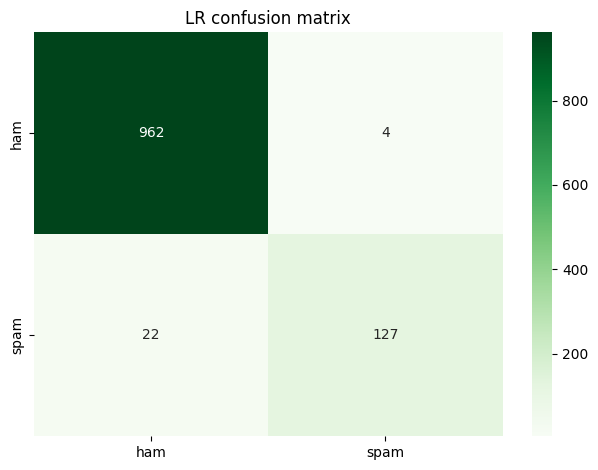

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       966
        spam       0.97      0.85      0.91       149

    accuracy                           0.98      1115
   macro avg       0.97      0.92      0.95      1115
weighted avg       0.98      0.98      0.98      1115



In [6]:
winner = max(results, key=lambda k: results[k]["f1"])
final = MultinomialNB() if winner == "NB" else LogisticRegression(max_iter=2000, C=4.0)
final.fit(Xtr, y_train)
pred = final.predict(Xte)

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.title(f"{winner} confusion matrix")
plt.tight_layout(); plt.savefig(ART / f"cm_{winner}.png", dpi=120); plt.show()
print(classification_report(y_test, pred, target_names=["ham", "spam"]))


## Notes

LR edged out NB by a small margin on F1, but the gap is well within CV std. For a production filter the right call is probably NB on training cost alone, plus it's easier to update with new examples (just bump the count tables). The pile of false negatives is again dominated by very short messages — adding the raw character length as a separate feature would probably help and I didn't bother.
